In [23]:
import pandas as pd
from scipy.stats import chi2_contingency
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats

In [24]:
df = pd.read_csv("../data/amz_uk_price_prediction_dataset.csv")
df.head()

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


# Part 1: Analyzing Best-Seller Trends Across Product Categories

In [25]:
crosstab = pd.crosstab(df['category'], df['isBestSeller'])

crosstab.head()

isBestSeller,False,True
category,,
3D Printers,247,1
3D Printing & Scanning,4065,2
Abrasive & Finishing Products,245,5
Action Cameras,1696,1
Adapters,251,3


In [26]:
crosstab['total'] = crosstab.sum(axis=1)
crosstab['best_seller_ratio'] = crosstab[True] / crosstab['total']

crosstab_sorted = crosstab.sort_values(by='best_seller_ratio', ascending=False)

crosstab_sorted.head(10)

isBestSeller,False,True,total,best_seller_ratio
category,,,,
Grocery,9008,556,9564,0.058135
Smart Home Security & Lighting,98,6,104,0.057692
Health & Personal Care,9017,552,9569,0.057686
Mobile Phone Accessories,248,11,259,0.042471
Power & Hand Tools,8353,306,8659,0.035339
"Billiard, Snooker & Pool",241,8,249,0.032129
Pet Supplies,9152,285,9437,0.030200
Home Brewing & Wine Making,239,7,246,0.028455
Wind Instruments,243,7,250,0.028000


In [27]:
table = pd.crosstab(df['category'], df['isBestSeller'])

chi2, p, dof, expected = chi2_contingency(table)

print("Chi-square:", chi2)
print("p-value:", p)

Chi-square: 36540.20270061387
p-value: 0.0


In [28]:
n = table.sum().sum()
min_dim = min(table.shape) - 1

cramers_v = np.sqrt(chi2 / (n * min_dim))

print("Cramér's V:", cramers_v)

Cramér's V: 0.1222829439760564


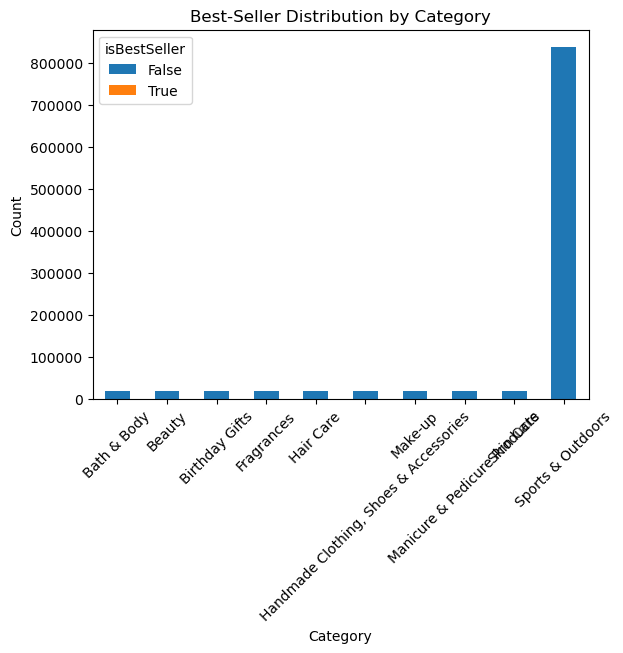

In [29]:
top_categories = df['category'].value_counts().head(10).index

filtered = df[df['category'].isin(top_categories)]

stacked = pd.crosstab(filtered['category'], filtered['isBestSeller'])

stacked.plot(kind='bar', stacked=True)

plt.title("Best-Seller Distribution by Category")
plt.xlabel("Category")
plt.ylabel("Count")

plt.xticks(rotation=45)

plt.show()

# Part 2: Exploring Product Prices and Ratings Across Categories and Brands

In [30]:
Q1 = df['price'].quantile(0.25)
Q3 = df['price'].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

df_clean = df[(df['price'] >= lower_bound) & (df['price'] <= upper_bound)]

print("Original size:", df.shape)
print("Clean size:", df_clean.shape)

Original size: (2443651, 9)
Clean size: (2115963, 9)


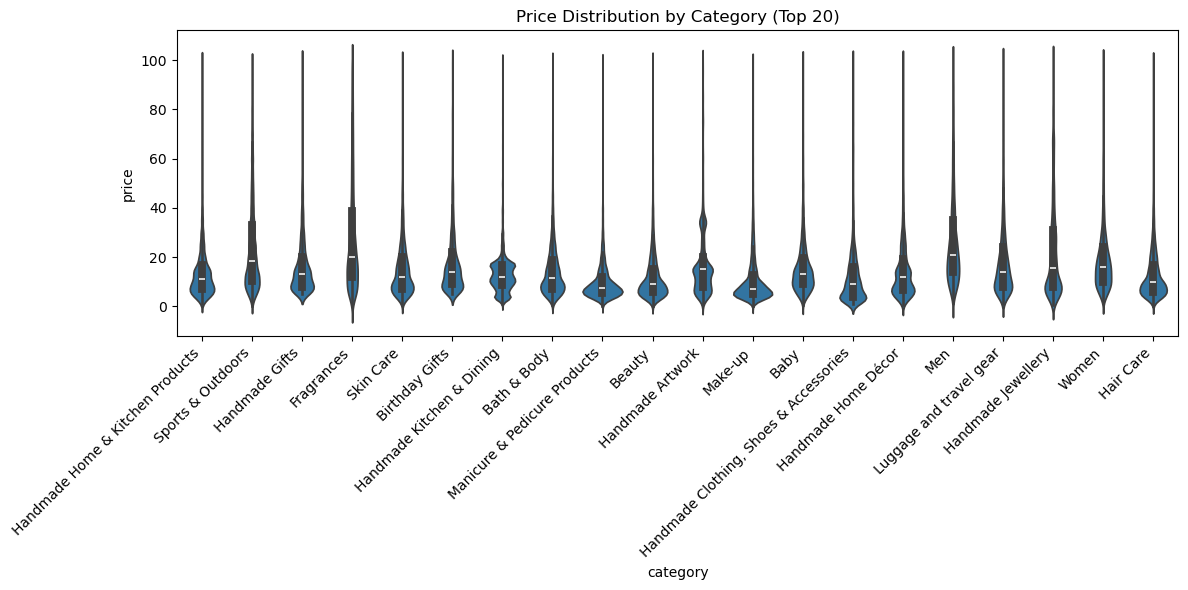

In [32]:
top20 = df_clean['category'].value_counts().head(20).index

df_top20 = df_clean[df_clean['category'].isin(top20)]

plt.figure(figsize=(12,6))
sns.violinplot(data=df_top20, x='category', y='price')

plt.title("Price Distribution by Category (Top 20)")
plt.xticks(rotation=45, ha='right')

plt.tight_layout()
plt.show()

In [33]:
median_prices = df_clean.groupby('category')['price'].median().sort_values(ascending=False)

print(median_prices.head(10))

category
Desktop PCs               74.00
Boxing Shoes              69.79
Tablets                   69.00
Graphics Cards            68.54
Motherboards              67.92
Made in Italy Handmade    64.00
Digital Frames            63.90
Streaming Clients         62.68
Golf Shoes                62.39
Ski Helmets               61.33
Name: price, dtype: float64


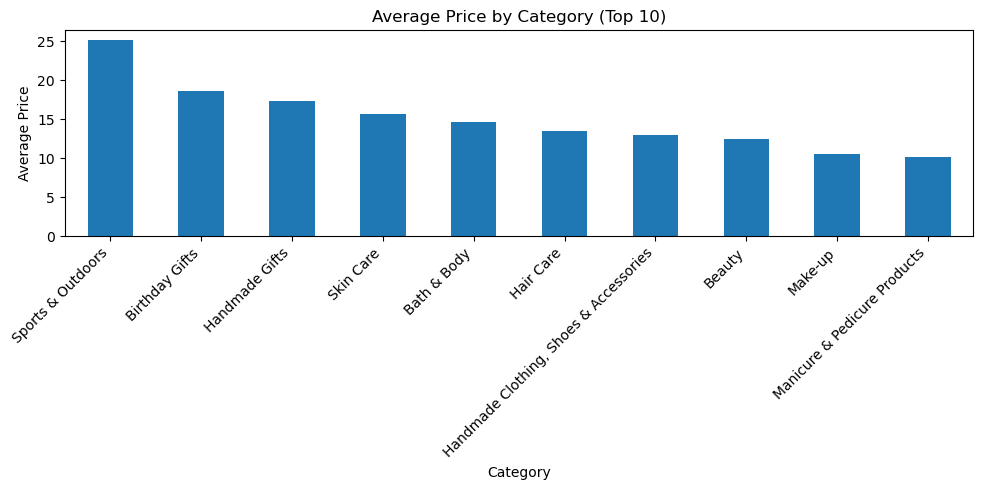

In [34]:
top10 = df_clean['category'].value_counts().head(10).index

df_top10 = df_clean[df_clean['category'].isin(top10)]

avg_price = df_top10.groupby('category')['price'].mean().sort_values(ascending=False)

avg_price.plot(kind='bar', figsize=(10,5))

plt.title("Average Price by Category (Top 10)")
plt.xlabel("Category")
plt.ylabel("Average Price")

plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [35]:
avg_all = df_clean.groupby('category')['price'].mean().sort_values(ascending=False)

print(avg_all.head(10))

category
Motherboards         68.772432
Boxing Shoes         67.417803
Desktop PCs          66.915562
Tablets              66.552971
Graphics Cards       65.103509
Digital Frames       60.745129
Streaming Clients    60.241803
Hockey Shoes         60.094796
Computer Cases       58.339884
Skiing Poles         57.867770
Name: price, dtype: float64


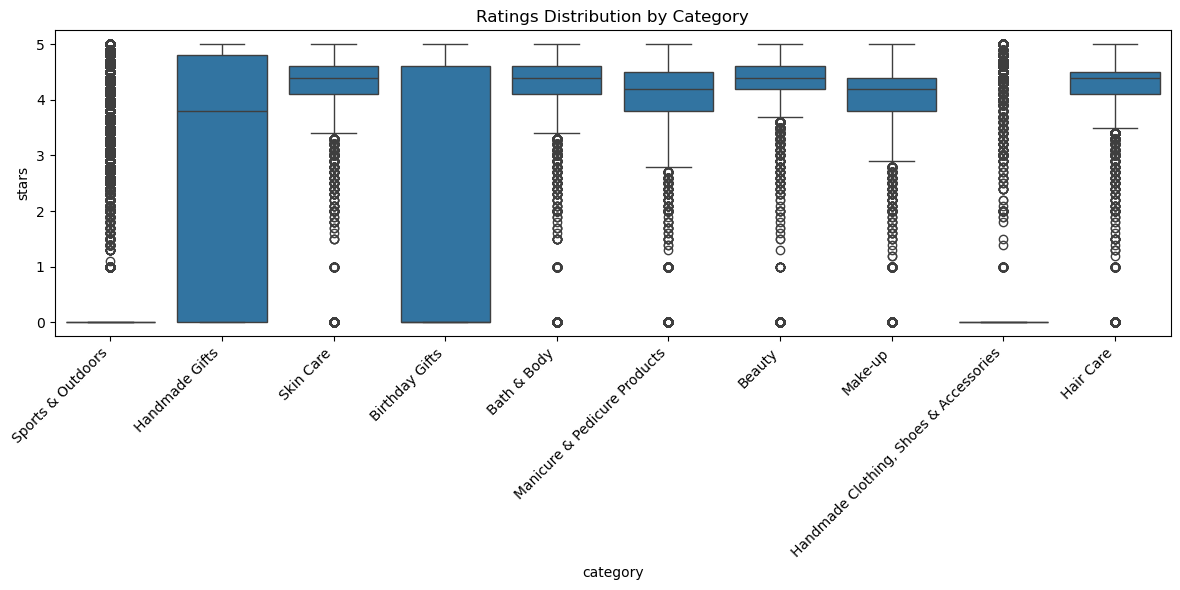

In [37]:
df_top10_cat = df[df['category'].isin(top10)]

plt.figure(figsize=(12,6))
sns.boxplot(data=df_top10_cat, x='category', y='stars')

plt.title("Ratings Distribution by Category")
plt.xticks(rotation=45, ha='right')

plt.tight_layout()
plt.show()

In [38]:
median_ratings = df.groupby('category')['stars'].median().sort_values(ascending=False)

print(median_ratings.head(10))

category
Computer Memory                 4.7
Hobbies                         4.6
Beer, Wine & Spirits            4.6
Laptop Accessories              4.6
Kids' Play Figures              4.6
Building & Construction Toys    4.6
CPUs                            4.6
Office Paper Products           4.6
Luxury Food & Drink             4.6
Camera & Photo Accessories      4.5
Name: stars, dtype: float64


# Part 3: Investigating the Interplay Between Product Prices and Ratings

In [39]:
corr_value = df['price'].corr(df['stars'])
print("Correlation:", corr_value)

Correlation: -0.1249067326214861


This suggests that there is no significant correlation between product price and customer ratings.

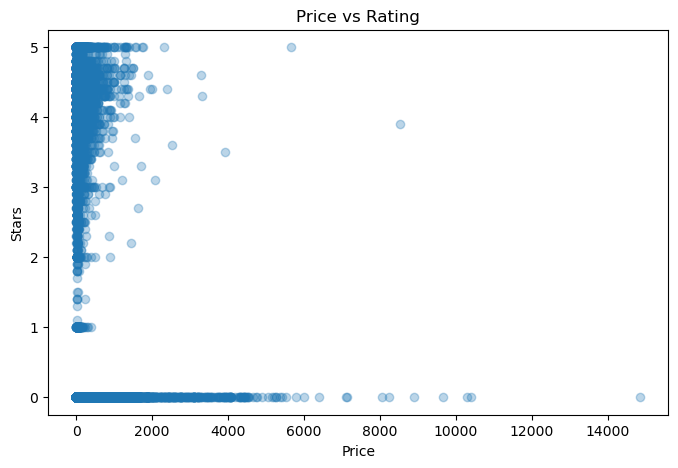

In [41]:
df_sample = df.sample(50000)

plt.figure(figsize=(8,5))
plt.scatter(df_sample['price'], df_sample['stars'], alpha=0.3)

plt.title("Price vs Rating")
plt.xlabel("Price")
plt.ylabel("Stars")

plt.show()

Most products are concentrated at lower price ranges, with ratings typically between 4 and 5 stars, indicating generally positive feedback regardless of price.

Additionally, there is a noticeable cluster of products with zero ratings, spread across different price levels, which further weakens any visible relationship.

Overall, the scatter plot confirms that there is no strong relationship between price and ratings.

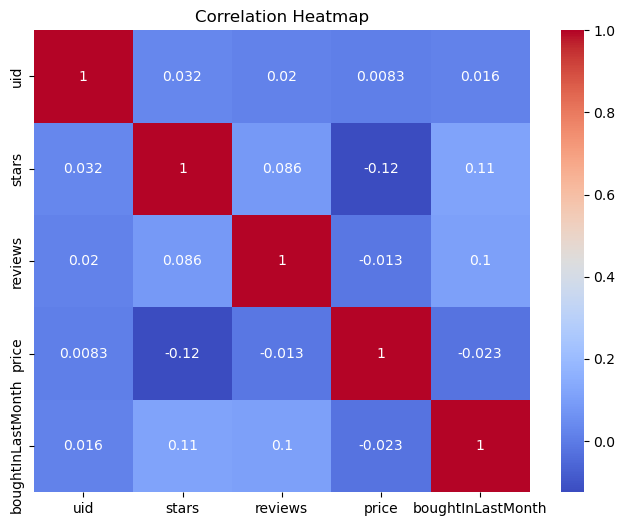

In [42]:
numeric_df = df.select_dtypes(include=['float64', 'int64'])

plt.figure(figsize=(8,6))
sns.heatmap(numeric_df.corr(), annot=True, cmap='coolwarm')

plt.title("Correlation Heatmap")
plt.show()

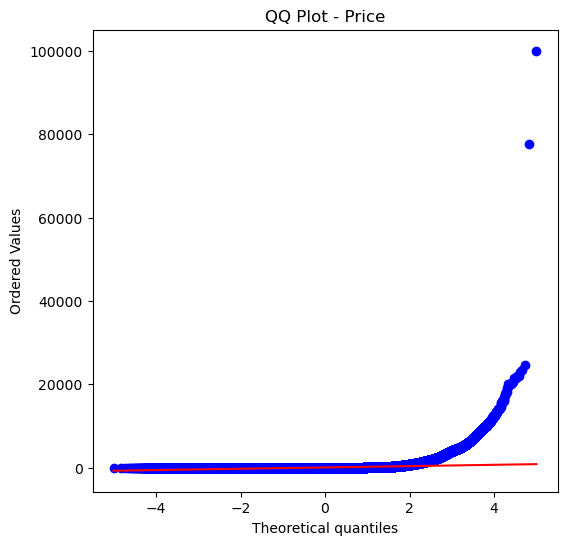

In [43]:
plt.figure(figsize=(6,6))
stats.probplot(df['price'], dist="norm", plot=plt)

plt.title("QQ Plot - Price")
plt.show()

Here we can see that product prices do not follow a normal distribution and are instead heavily right-skewed, with the presence of extreme high-value outliers.